# 선석점유율

선석 점유율 = Σ 작업시간 ÷ (선석 수 × 기간 시간) × 100

In [1]:
# 작업시간 = 재항시간-추정대기시간
# 추정대기시간 = max(0,이전 배 출항 - 현재 배 입항)



In [2]:
import pandas as pd

df = pd.read_csv(
    "../data/record.csv",
    encoding="utf-8-sig"
)

print(df.head())

    호출부호              선명    입항횟수      총톤수                 입항일시  \
0  3FRF8     SONG YUN HE  2022.0   16,737  2022-01-01 00:48:00   
1  VRNA9  SEASPAN THAMES  2022.0  112,967  2022-01-01 02:00:00   
2  VRRP8  CMA CGM MUMBAI  2022.0  112,967  2022-01-01 03:00:00   
3  D5TL4       MSC JEWEL  2022.0  140,976  2022-01-01 03:22:00   
4  A8YT7        MALIAKOS  2022.0   41,391  2022-01-01 03:35:00   

                  출항일시           CIQ수속일자              수리일시       MRN 번호  \
0  2022-01-03 01:52:00   2022-01-03 1:52  2022-01-03 15:58  22COHES152E   
1  2022-01-02 17:43:00  2022-01-02 17:43  2022-01-03 11:18  22HLCU4202E   
2  2022-01-02 04:06:00   2022-01-02 4:00  2022-01-03 11:22  22CMAL0030E   
3  2022-01-03 05:00:00   2022-01-03 5:00  2022-01-03 11:19  22MSCU0004E   
4  2022-01-01 16:45:00  2022-01-01 16:00  2022-01-03 11:07  22SMLME016E   

         계선장소         차항지       전출항지       재항시간  
0  신항 5부두 3선석     QINGDAO         광양  49.066667  
1  신항 3부두 4선석   VANCOUVER   SHANGHAI  39.716667  
2 

# 부두별 월별 총 재항시간

             1부두      2부두      3부두      4부두      5부두
월                                                   
2022-01  2009.32  3137.90  2108.45  1565.63  2382.03
2022-02  1795.40  3282.37  2052.67  1628.72  2613.52
2022-03  1657.17  3412.95  1978.02  2117.52  2647.33
2022-04  1891.30  3473.43  2062.47  1935.43  2522.78
2022-05  1956.22  3505.60  2004.22  2053.75  2515.72
2022-06  1781.70  2945.57  2081.38  1385.87  2591.43
2022-07  1932.23  3512.15  1971.62  1508.43  2233.22
2022-08  1811.27  3240.58  1531.12  1674.38  2250.88
2022-09  1736.28  2788.80  1456.47  1310.55  2379.53
2022-10  1625.05  2781.85  1420.28  1588.43  2817.93
2022-11  1440.72  2971.58  1441.23  1504.07  2446.82
2022-12  1560.65  3095.22  1476.92  1367.60  2095.98
2023-01  1603.08  3325.28  1791.58  1703.48  2399.12
2023-02  1575.73  3276.38  1592.65  1678.78  2083.32
2023-03  2053.25  3623.95  1985.08  1716.20  2028.53
2023-04  1912.70  3521.73  1801.97  1737.38  1878.28
2023-05  1683.78  4071.00  1829.87  1917.33  2

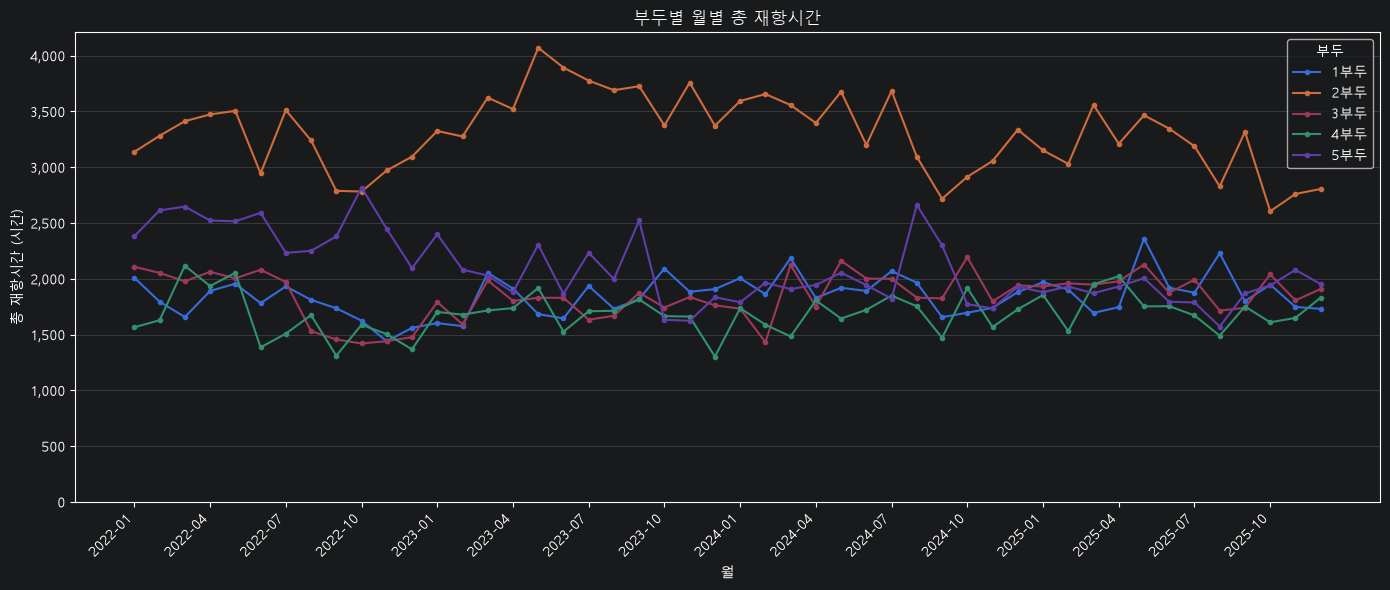

In [3]:
import pandas as pd

# CSV 파일을 파이썬 코드와 같은 폴더에 두세요.
df = pd.read_csv("../data/record.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

for col in ["입항일시", "출항일시"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두", expand=False
)
df["재항시간"] = (
    df["출항일시"] - df["입항일시"]
).dt.total_seconds() / 3600

# 날짜 누락·변환 실패·음수 시간·대상 외 부두 제외
data = df.loc[
    df["재항시간"].ge(0) & df["부두"].notna()
].copy()

# 분석 기간: 종료 시각은 포함하지 않음
start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")

months = pd.date_range(start, end, freq="MS", inclusive="left")
result = pd.DataFrame(
    index=months, columns=list("12345"), dtype=float
)

for month in months:
    next_month = month + pd.offsets.MonthBegin(1)

    # 각 선박의 재항 구간 중 해당 월과 겹치는 시간
    hours = (
        data["출항일시"].clip(upper=next_month)
        - data["입항일시"].clip(lower=month)
    ).dt.total_seconds().div(3600).clip(lower=0)

    result.loc[month] = (
        hours.groupby(data["부두"]).sum()
        .reindex(list("12345"), fill_value=0)
    )

result.index = result.index.strftime("%Y-%m")
result.index.name = "월"
result.columns = result.columns + "부두"

print(result.round(2).to_string())

# 월별·부두별 추이 그래프
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ax = result.plot(figsize=(14, 6), marker="o", markersize=3)
ax.set_title("부두별 월별 총 재항시간")
ax.set_xlabel("월")
ax.set_ylabel("총 재항시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두")
plt.xticks(rotation=45)
# 분기마다 날짜 표시
ticks = list(range(0, len(result), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    result.index[ticks],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

# 선석수

In [4]:
import pandas as pd

# 앞서 제공한 이미지 기준 선석 수
선석수 = {1: 3, 2: 6, 3: 4, 4: 4, 5: 4}

선석수표 = pd.DataFrame({
    "부두": list(선석수.keys()),
    "선석수": list(선석수.values())
})

print(선석수표.to_string(index=False))

 부두  선석수
  1    3
  2    6
  3    4
  4    4
  5    4


# 월별 부두가동률

In [6]:
from pathlib import Path

print("현재 작업 경로:", Path.cwd())
print("data 폴더 존재:", Path("data").exists())
print("CSV 파일 목록:", list(Path.cwd().rglob("*.csv")))

현재 작업 경로: C:\work\Final_Project\EDA
data 폴더 존재: False
CSV 파일 목록: []


In [7]:
from pathlib import Path

# 상위 폴더에 있는 CSV 파일 찾기
print(list(Path(r"C:\work\Final_Project").rglob("port_month.csv")))

[WindowsPath('C:/work/Final_Project/data/port_month.csv')]


부두          1부두     2부두     3부두     4부두     5부두
월                                              
2022-01  139.71  138.87  131.50  112.86  105.68
2022-02  141.58  134.83  122.46  121.58  102.58
2022-03  113.24  130.48  124.37  125.67   96.51
2022-04  135.64  137.40  128.51  122.30  103.22
2022-05  129.57  135.76  124.88  134.21  103.27
2022-06  124.58  125.84  121.67  106.54  105.71
2022-07  143.09  133.59  123.35  112.25  109.06
2022-08  134.08  127.37  105.51  117.13   99.89
2022-09  113.52  109.47   91.65   98.34   80.28
2022-10  118.87  116.50  100.92  121.40  102.30
2022-11  124.00  120.38  113.24  119.78  101.72
2022-12  124.50  118.05  101.43  111.64   86.86
2023-01  127.88  123.02  116.21  121.40  107.61
2023-02  140.96  127.95  121.89  124.28  111.66
2023-03  154.92  131.10  130.99  137.87  107.13
2023-04  147.86  134.83  133.78  126.71  108.70
2023-05  129.57  136.69  123.86  125.06  102.30
2023-06  128.07  131.30  125.88  123.56  105.71
2023-07  123.94  125.51  113.15  116.52 

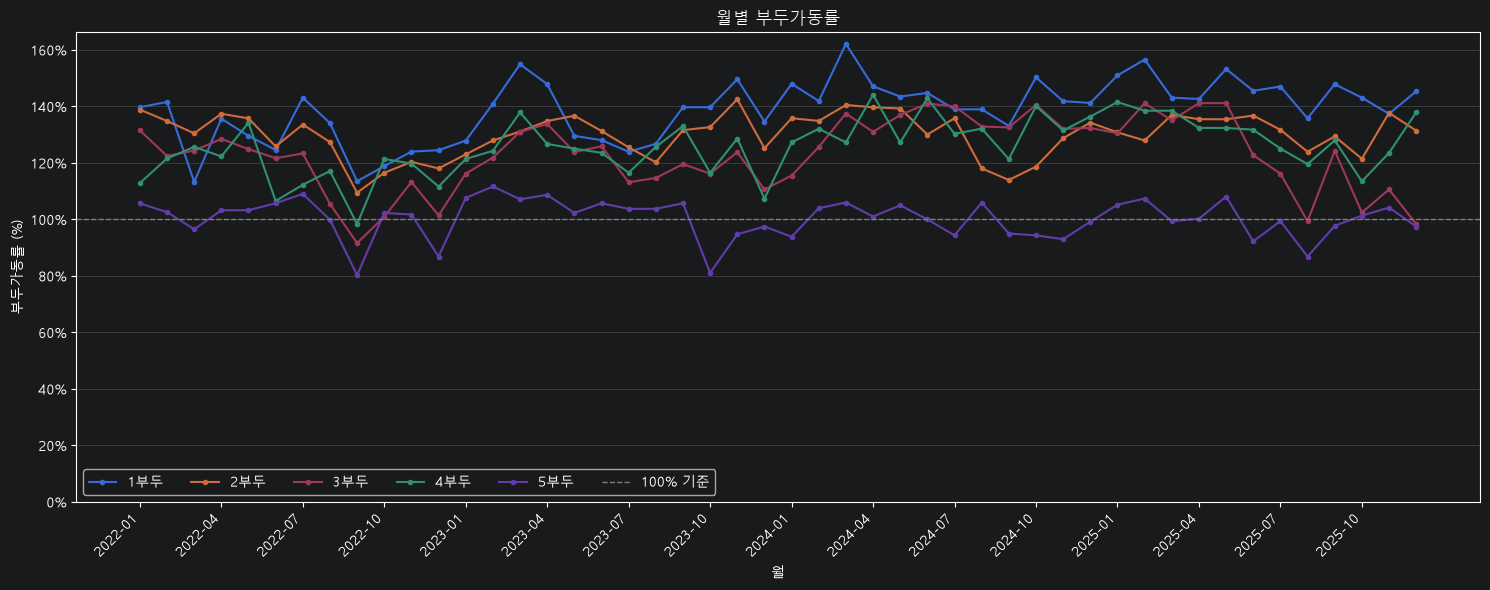

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = Path("../data/port_month.csv")
START_YEAR = 2022
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 실제 연도별 하역능력을 확보하면 수정하세요.
reference_capacity = {
    "1부두": 2_090_000,
    "2부두": 3_790_000,
    "3부두": 2_310_000,
    "4부두": 1_930_000,
    "5부두": 2_440_000
}

# 참고값을 2022~2025년 동일하게 적용하는 가정
capacity_by_year = {
    year: reference_capacity.copy()
    for year in range(START_YEAR, END_YEAR + 1)
}

# 2. 데이터 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.empty:
    raise ValueError("선택한 기간에 해당하는 자료가 없습니다.")

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

# 3. 부두별 자료를 세로 형태로 변환
monthly = df.melt(
    id_vars=["기준년도", "월"],
    value_vars=[
        "신항1부두",
        "신항2부두",
        "신항3부두",
        "신항4부두",
        "신항5부두"
    ],
    var_name="부두",
    value_name="처리량_천TEU"
)

monthly["부두"] = monthly["부두"].str.replace(
    "신항", "", regex=False
)

monthly["기준월"] = pd.to_datetime({
    "year": monthly["기준년도"],
    "month": monthly["월"],
    "day": 1
})

# 천TEU → TEU
monthly["실제 처리실적(TEU)"] = (
    pd.to_numeric(monthly["처리량_천TEU"], errors="coerce")
    * 1000
)

# 4. 실제 달력 기준 월별·연간 일수
monthly["월 일수"] = monthly["기준월"].dt.days_in_month
monthly["연간 일수"] = (
    monthly["기준월"].dt.is_leap_year
    .map({True: 366, False: 365})
)

monthly["연간 하역능력(TEU)"] = monthly.apply(
    lambda row: capacity_by_year[int(row["기준년도"])][row["부두"]],
    axis=1
)

capacity = monthly["연간 하역능력(TEU)"]

if capacity.isna().any() or capacity.le(0).any():
    raise ValueError("연간 하역능력은 양수로 입력해야 합니다.")

# 5. 월별 환산 하역능력 및 가동률
monthly["월별 환산 하역능력(TEU)"] = (
    monthly["연간 하역능력(TEU)"]
    * monthly["월 일수"]
    / monthly["연간 일수"]
)

monthly["월별 부두가동률(%)"] = (
    monthly["실제 처리실적(TEU)"]
    / monthly["월별 환산 하역능력(TEU)"]
    * 100
)

# 6. 월별·부두별 결과 표
monthly_rate = monthly.pivot(
    index="기준월",
    columns="부두",
    values="월별 부두가동률(%)"
).reindex(columns=list(reference_capacity))

# 누락된 월은 0으로 채우지 않고 결측으로 유지
all_months = pd.date_range(
    f"{START_YEAR}-01-01",
    f"{END_YEAR}-12-01",
    freq="MS"
)

monthly_rate = monthly_rate.reindex(all_months)
monthly_rate.index = monthly_rate.index.strftime("%Y-%m")
monthly_rate.index.name = "월"

print(monthly_rate.round(2).to_string())

# 7. 라인그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(15, 6))

for terminal in monthly_rate.columns:
    ax.plot(
        monthly_rate.index,
        monthly_rate[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

# 분기 간격: 매년 1·4·7·10월
ticks = list(range(0, len(monthly_rate), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    monthly_rate.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_title("월별 부두가동률")
ax.set_xlabel("월")
ax.set_ylabel("부두가동률 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(bottom=0)

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="100% 기준"
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=6)

plt.tight_layout()
plt.show()

# 1부두는 신항 1~5부두 중 가장 여유가 없다

   기준년도  월  신항1부두  신항2부두  신항3부두  신항4부두  신항5부두  신항6부두  신항7부두    단위
0  2017  1    213    444     62    206    144    NaN    NaN  천TEU
1  2017  2    197    402     69    200    116    NaN    NaN  천TEU
2  2017  3    221    396    103    228    150    NaN    NaN  천TEU
3  2017  4    247    319    257    203    136    NaN    NaN  천TEU
4  2017  5    236    376    229    190    170    NaN    NaN  천TEU
           1       2       3       4       5
기준년도                                        
2019  109.81  145.17  120.52  112.28   86.84
2020  131.34  127.63  127.84  109.33   87.38
2021  130.86  134.17  127.32  116.06   94.80
2022  128.47  127.36  115.76  116.99   99.75
2023  136.89  130.18  120.82  123.83  102.38
2024  144.35  130.82  133.20  132.69   99.30
2025  145.65  131.58  121.73  130.16   99.92


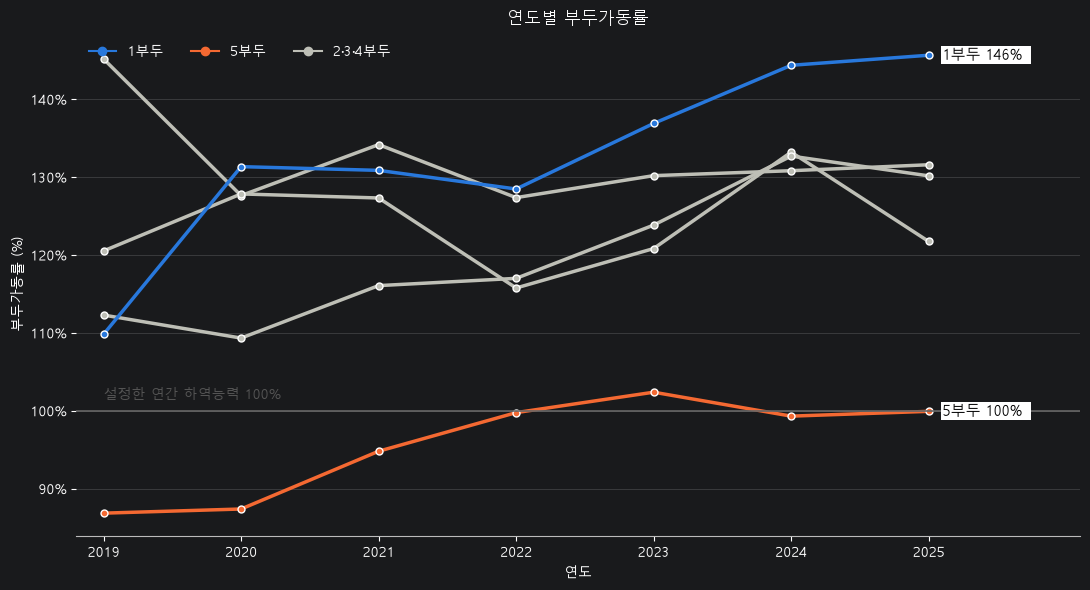

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# 1. 설정


DATA_PATH = Path(r"C:\work\Final_Project\data\port_month.csv")

df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

print(df.head())
START_YEAR = 2019
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 모든 연도에 동일하게 적용하는 가정
annual_capacity = pd.Series({
    "1": 2_090_000,
    "2": 3_790_000,
    "3": 2_310_000,
    "4": 1_930_000,
    "5": 2_440_000
})

# 2. 월별 처리량 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

years = list(range(START_YEAR, END_YEAR + 1))

month_counts = (
    df.groupby("기준년도")["월"]
    .nunique()
    .reindex(years, fill_value=0)
)

if not month_counts.eq(12).all():
    raise ValueError("12개월 자료가 없는 연도가 있습니다.")

columns = [f"신항{x}부두" for x in annual_capacity.index]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3. 월별 천TEU → 연간 TEU
annual_teu = (
    df.groupby("기준년도")[columns]
    .sum(min_count=12)
    .reindex(years)
    * 1000
)

if annual_teu.isna().any().any():
    raise ValueError("처리량에 누락된 값이 있습니다.")

annual_teu.columns = annual_capacity.index

# 연간 부두가동률
annual_rate = annual_teu.div(
    annual_capacity, axis="columns"
) * 100

print(annual_rate.round(2).to_string())

# 4. 그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(11, 6))

colors = {
    "1": "#2878DC",
    "2": "#BEBFB6",
    "3": "#BEBFB6",
    "4": "#BEBFB6",
    "5": "#F46932"
}

for terminal in ["2", "3", "4", "5", "1"]:
    ax.plot(
        annual_rate.index,
        annual_rate[terminal],
        color=colors[terminal],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        linewidth=2.5
    )

# 하역능력 100% 기준선
ax.axhline(100, color="#666666", linewidth=1.2)
ax.text(
    START_YEAR,
    101.5,
    "설정한 연간 하역능력 100%",
    fontsize=10,
    color="#555555"
)

# 마지막 연도의 1·5부두 값 표시
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.text(
        END_YEAR + 0.15,
        value,
        f"{terminal}부두 {value:.0f}%",
        va="center",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 범례
handles = [
    Line2D(
        [0], [0], color=colors["1"],
        marker="o", label="1부두"
    ),
    Line2D(
        [0], [0], color=colors["5"],
        marker="o", label="5부두"
    ),
    Line2D(
        [0], [0], color=colors["2"],
        marker="o", label="2·3·4부두"
    )
]

ax.legend(
    handles=handles,
    ncol=3,
    frameon=False,
    loc="upper left"
)

ax.set_title("연도별 부두가동률")
ax.set_xlabel("연도")
ax.set_ylabel("부두가동률 (%)")
ax.set_xticks(years)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("#BBBBBB")

# 마지막 연도 값 표시: 소수점 없이 반올림
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.annotate(
        f"{terminal}부두 {value:.0f}%",
        xy=(END_YEAR, value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 오른쪽 글자가 들어갈 공간 확보
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)

plt.tight_layout()
plt.show()

# 1부두의 늘어난 재항시간은 늘어난 물량이었다

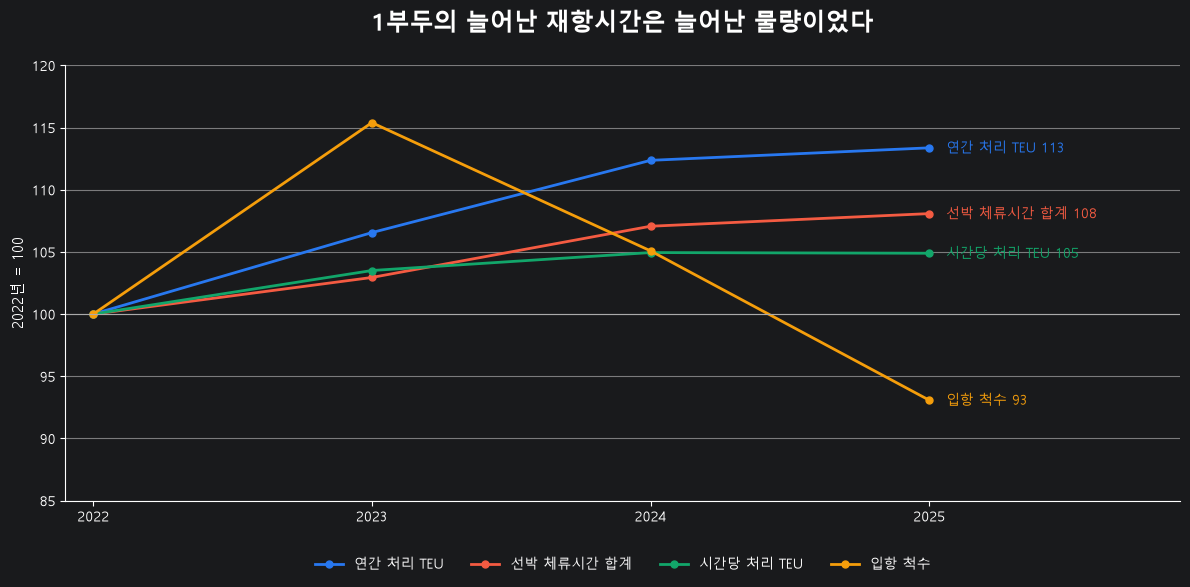


[연도별 실제 수치]
      입항척수  선박체류시간합계  연간처리TEU  시간당처리TEU
연도                                     
2022   708  21211.08  2685000    126.58
2023   817  21836.02  2861000    131.02
2024   744  22709.90  3017000    132.85
2025   659  22925.35  3044000    132.78

[2022년 = 100 지수]
      연간처리TEU  선박체류시간합계  시간당처리TEU   입항척수
연도                                      
2022    100.0     100.0     100.0  100.0
2023    106.6     102.9     103.5  115.4
2024    112.4     107.1     104.9  105.1
2025    113.4     108.1     104.9   93.1


In [15]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ======================================
# 1. 기본 설정
# ======================================

DATA_DIR = Path(r"C:\work\Final_Project\data")

PORT_PATH = DATA_DIR / "port_month.csv"
RECORD_PATH = DATA_DIR / "record.csv"

START_YEAR = 2022
END_YEAR = 2025

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ======================================
# 2. 월별 물동량 불러오기
# ======================================

port = pd.read_csv(PORT_PATH, encoding="cp949")
port.columns = port.columns.str.strip()

port["기준년도"] = pd.to_numeric(
    port["기준년도"], errors="coerce"
)

port["신항1부두"] = pd.to_numeric(
    port["신항1부두"].astype(str).str.replace(",", ""),
    errors="coerce"
)

port = port[
    port["기준년도"].between(START_YEAR, END_YEAR)
].copy()

# 천 TEU를 실제 TEU 단위로 변환
annual_teu = (
    port.groupby("기준년도")["신항1부두"]
    .sum() * 1000
)

annual_teu.index = annual_teu.index.astype(int)

# ======================================
# 3. 선박 입출항 기록 불러오기
# ======================================

record = pd.read_csv(
    RECORD_PATH, encoding="utf-8-sig"
)

record.columns = record.columns.str.strip()

# 신항 1부두만 선택
record = record[
    record["계선장소"].astype(str).str.contains(
        r"신항\s*1부두\s*\d+선석",
        regex=True,
        na=False
    )
].copy()

# 날짜 변환
record["입항일시"] = pd.to_datetime(
    record["입항일시"], errors="coerce"
)

record["출항일시"] = pd.to_datetime(
    record["출항일시"], errors="coerce"
)

# 재항시간 계산 (시간)
record["재항시간"] = (
    record["출항일시"] - record["입항일시"]
).dt.total_seconds() / 3600

record["연도"] = record["입항일시"].dt.year

record = record[
    record["연도"].between(START_YEAR, END_YEAR)
    & (record["재항시간"] >= 0)
].copy()

# ======================================
# 4. 연도별 지표 계산
# ======================================

annual = record.groupby("연도").agg(
    입항척수=("입항일시", "count"),
    선박체류시간합계=("재항시간", "sum")
)

annual["연간처리TEU"] = annual_teu

# 시간당 처리 TEU
annual["시간당처리TEU"] = (
    annual["연간처리TEU"] /
    annual["선박체류시간합계"]
)

# 2022~2025 순서 정리
annual = annual.reindex(
    range(START_YEAR, END_YEAR + 1)
)

# ======================================
# 5. 2022년 = 100 지수화
# ======================================

columns = [
    "연간처리TEU",
    "선박체류시간합계",
    "시간당처리TEU",
    "입항척수"
]

base = annual.loc[2022, columns]

index_df = annual[columns].div(base).mul(100)

# ======================================
# 6. 사진과 같은 라인그래프
# ======================================

fig, ax = plt.subplots(figsize=(12, 6))

styles = {
    "연간처리TEU": {
        "label": "연간 처리 TEU",
        "color": "#2878F0"
    },
    "선박체류시간합계": {
        "label": "선박 체류시간 합계",
        "color": "#F45B42"
    },
    "시간당처리TEU": {
        "label": "시간당 처리 TEU",
        "color": "#12A66A"
    },
    "입항척수": {
        "label": "입항 척수",
        "color": "#F59E0B"
    }
}

for col, style in styles.items():
    ax.plot(
        index_df.index,
        index_df[col],
        label=style["label"],
        color=style["color"],
        linewidth=2,
        marker="o",
        markersize=5
    )

# 2025년 마지막 값 표시
for col, style in styles.items():
    value = index_df.loc[2025, col]

    ax.annotate(
        f"{style['label']} {value:.0f}",
        xy=(2025, value),
        xytext=(12, 0),
        textcoords="offset points",
        color=style["color"],
        fontsize=10,
        va="center"
    )

# 기준선
ax.axhline(
    100,
    color="#AAAAAA",
    linewidth=0.8
)

ax.set_title(
    "1부두의 늘어난 재항시간은 늘어난 물량이었다",
    fontsize=17,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("")
ax.set_ylabel("2022년 = 100", fontsize=11)

ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xlim(2021.9, 2025.9)
ax.set_ylim(85, 120)

ax.grid(
    axis="y",
    color="#DDDDDD",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()

# ======================================
# 7. 분석 결과 확인
# ======================================

print("\n[연도별 실제 수치]")
print(annual.round(2).to_string())

print("\n[2022년 = 100 지수]")
print(index_df.round(1).to_string())


# 1부두 전체 선석점유율

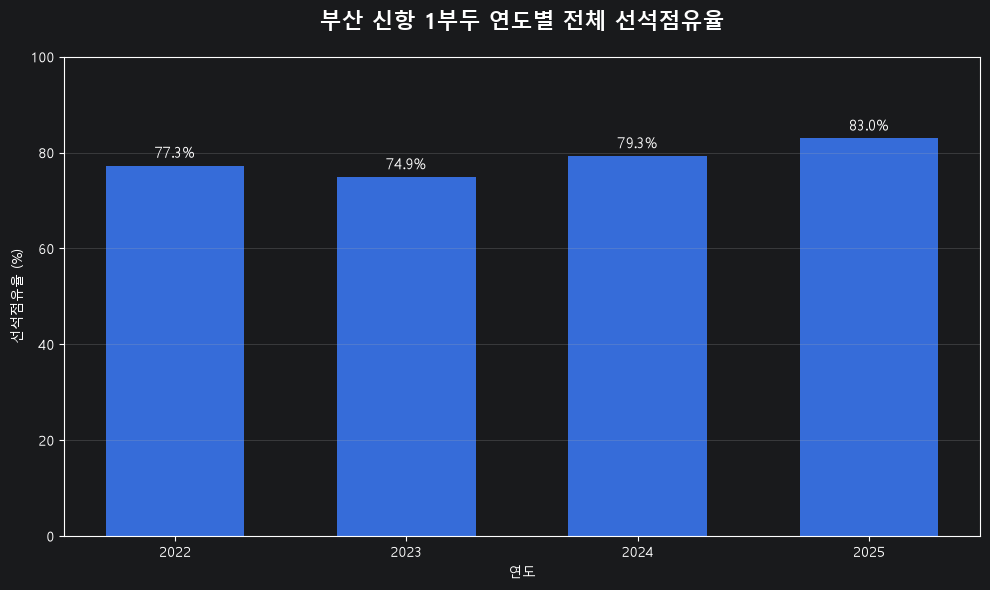


[1부두 전체 선석점유율]
  연도    총작업시간  선석점유율
2022 20309.07  77.28
2023 19680.70  74.89
2024 20889.98  79.27
2025 21799.53  82.95


In [17]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==================================
# 1. 기본 설정
# ==================================

DATA_PATH = Path(r"C:\work\Final_Project\data\port1.csv")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ==================================
# 2. 데이터 불러오기
# ==================================

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

df["접안"] = pd.to_datetime(
    df["접안(예정)일시"], errors="coerce"
)

df["출항"] = pd.to_datetime(
    df["출항(예정)일시"], errors="coerce"
)

df["선석"] = pd.to_numeric(
    df["선석"], errors="coerce"
)

# 1~3선석만 선택
df = df[df["선석"].isin([1, 2, 3])].copy()

# 잘못된 시간 데이터 제거
df = df.dropna(subset=["접안", "출항"])
df = df[df["출항"] >= df["접안"]].copy()

# ==================================
# 3. 연도별 전체 선석점유율 계산
# ==================================

results = []

BERTH_COUNT = 3

for year in range(2022, 2026):

    year_start = pd.Timestamp(year, 1, 1)
    year_end = pd.Timestamp(year + 1, 1, 1)

    # 해당 연도와 겹치는 작업 기록
    temp = df[
        (df["접안"] < year_end) &
        (df["출항"] > year_start)
    ].copy()

    # 연도 범위 안에 해당하는 작업시간만 계산
    temp["시작"] = temp["접안"].clip(lower=year_start)
    temp["종료"] = temp["출항"].clip(upper=year_end)

    temp["작업시간"] = (
        temp["종료"] - temp["시작"]
    ).dt.total_seconds() / 3600

    total_work_hours = temp["작업시간"].sum()

    # 윤년 포함 연간 총시간
    year_hours = (
        year_end - year_start
    ).total_seconds() / 3600

    # 전체 선석점유율
    occupancy = (
        total_work_hours /
        (BERTH_COUNT * year_hours)
    ) * 100

    results.append({
        "연도": year,
        "총작업시간": total_work_hours,
        "선석점유율": occupancy
    })

result = pd.DataFrame(results)

# ==================================
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    result["연도"].astype(str),
    result["선석점유율"],
    width=0.6
)

for bar, value in zip(bars, result["선석점유율"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("부산 신항 1부두 연도별 전체 선석점유율", fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("연도")
ax.set_ylabel("선석점유율 (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
# ==================================
# 5. 결과 출력
# ==================================

print("\n[1부두 전체 선석점유율]")
print(result.round(2).to_string(index=False))


# 1부두 평균재항시간

In [ ]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두",
    expand=False
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df["입항"].ge("2022-01-01")
    & df["입항"].lt("2026-01-01")
    & df["출항"].ge(df["입항"])
].copy()

# 실제 출항까지의 재항시간
data["재항시간"] = (
    data["출항"] - data["입항"]
).dt.total_seconds() / 3600

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 평균 재항시간: {data['재항시간'].mean():.2f}시간")

# 1부두 평균추정대기시간

In [ ]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df[["선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
].copy()

# 기간 필터링 전에 같은 선석의 직전 선박 확인
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 추정대기 = max(0, 직전 선박 출항 - 현재 선박 입항)
data["추정대기시간"] = (
    (data["앞배_출항"] - data["입항"])
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
    .fillna(0)
)

data = data.loc[
    data["입항"].ge("2022-01-01")
    & data["입항"].lt("2026-01-01")
].copy()

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 총 추정대기시간: {data['추정대기시간'].sum():.2f}시간")
print(f"1부두 평균 추정대기시간: {data['추정대기시간'].mean():.2f}시간")

In [ ]:
import pandas as pd

df = pd.read_csv("../data/port1.csv", encoding="utf-8-sig")

df.head()

# 부두별 선석별 평균작업시간

4부두: 오류·누락 1건 제외

2022~2025년 부두별·선석별 평균 작업시간
 부두  선석  기록수  평균작업시간_시간
  1   1 1110      22.96
  1   2  975      28.45
  1   3  843      34.93
  2   4 1710      17.53
  2   5 1536      19.70
  2   6 1303      23.73
  2   7 1136      27.36
  2   8 1041      30.11
  3   1 1244      23.74
  3   2 1332      16.49
  3   3  740      29.51
  3   4  456      19.21
  4   1 1069      19.18
  4   2 1135      23.45
  4   3 1215      22.62
  5   1 1362      21.60
  5   2 1074      26.04
  5   3  372      20.64
  5   4 1064      25.33


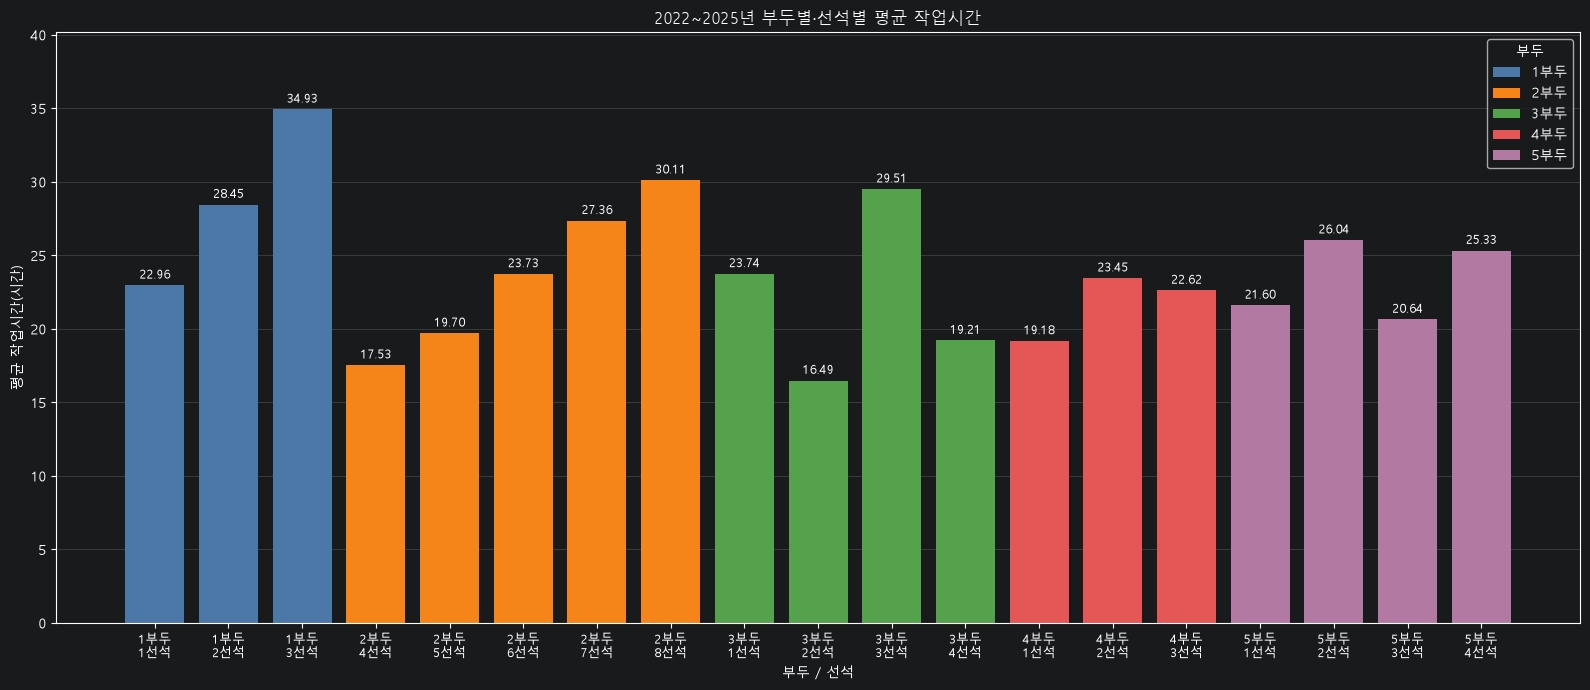

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. 한글 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. 파일 불러오기
DATA_DIR = r"C:\work\Final_Project\data"

port1 = pd.read_csv(DATA_DIR + "/port1.csv", encoding="utf-8-sig")
port2 = pd.read_csv(DATA_DIR + "/port2.csv", encoding="cp949")
port3 = pd.read_csv(DATA_DIR + "/port3.csv", encoding="cp949")
port4 = pd.read_csv(DATA_DIR + "/port4.csv", encoding="cp949")
port5 = pd.read_csv(DATA_DIR + "/port5.csv", encoding="cp949")

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")

ports = [
    (1, port1),
    (2, port2),
    (3, port3),
    (4, port4),
    (5, port5),
]

frames = []

# 3. 작업시간 계산
for number, port in ports:
    data = port.copy()

    data = data.rename(columns={
        "접안(예정)일시": "접안시각",
        "출항(예정)일시": "출항시각",
    })

    for col in ["접안시각", "출항시각"]:
        data[col] = pd.to_datetime(
            data[col],
            format="%Y-%m-%d %H:%M",
            errors="raise",
        )

    # 시각·선석 누락 또는 출항이 접안보다 빠른 기록 제외
    invalid = (
        data[["접안시각", "출항시각", "선석"]].isna().any(axis=1)
        | (data["출항시각"] < data["접안시각"])
    )

    if invalid.any():
        print(f"{number}부두: 오류·누락 {invalid.sum()}건 제외")

    data = data.loc[~invalid].copy()
    data["부두"] = number

    # 2022~2025년에 포함되는 구간만 계산
    work_start = data["접안시각"].clip(lower=START)
    work_end = data["출항시각"].clip(upper=END)

    # 작업시간 = 출항 - 접안 (시간 단위)
    data["작업시간_시간"] = (
        work_end - work_start
    ).dt.total_seconds() / 3600

    data = data.loc[data["작업시간_시간"] > 0]

    frames.append(data[["부두", "선석", "작업시간_시간"]])

# 4. 부두별·선석별 평균 작업시간
detail = pd.concat(frames, ignore_index=True)

result = (
    detail.groupby(["부두", "선석"], as_index=False)
    .agg(
        기록수=("작업시간_시간", "count"),
        평균작업시간_시간=("작업시간_시간", "mean"),
    )
    .sort_values(["부두", "선석"])
)

print("\n2022~2025년 부두별·선석별 평균 작업시간")
print(result.round(2).to_string(index=False))

# 5. 평균 작업시간 바그래프
labels = (
    result["부두"].astype(str) + "부두\n"
    + result["선석"].astype(str) + "선석"
)

port_colors = {
    1: "#4C78A8",
    2: "#F58518",
    3: "#54A24B",
    4: "#E45756",
    5: "#B279A2",
}

fig, ax = plt.subplots(figsize=(16, 7))

bars = ax.bar(
    labels,
    result["평균작업시간_시간"],
    color=result["부두"].map(port_colors),
)

ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_title("2022~2025년 부두별·선석별 평균 작업시간")
ax.set_xlabel("부두 / 선석")
ax.set_ylabel("평균 작업시간(시간)")
ax.set_ylim(0, result["평균작업시간_시간"].max() * 1.15)
ax.tick_params(axis="x", labelsize=9)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.legend(
    handles=[
        Patch(facecolor=color, label=f"{number}부두")
        for number, color in port_colors.items()
    ],
    title="부두",
)

plt.tight_layout()
plt.show()